# Exercise 15: K-means Clustering
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

Based on **Practice 21**, do the following on the **Iris dataset** (`load_iris`),
which contains **150 samples**, **4 features**, and **3 classes** (`setosa`, `versicolor`, `virginica`).

Use `init='k-means++'`, `n_init=10`, and `random_state=2026` for every K-means run.

Do NOT use the class labels during clustering. Only use them at the end for interpretation.

1) Load the Iris dataset (use all 4 features).

2) Standardize the features with `StandardScaler`.

3) Sweep `K` over `[2, 3, 4, 5, 6, 7, 8]`. For each `K`:
   - Fit K-means with `init='k-means++'`, `n_init=10`, `random_state=2026`.
   - Record the **distortion** (`inertia_`) and the **silhouette score**
     (`sklearn.metrics.silhouette_score`).

4) Plot two figures:
   - Distortion vs. K (elbow curve).
   - Silhouette score vs. K.

5) Choose **the K that maximizes the silhouette score** as `best_K`.
   Report `best_K` and the corresponding silhouette score.

6) Fit K-means with `n_clusters = best_K` and report:
   - The final distortion `J`.
   - The cluster sizes (count per cluster).

7) Visualize the resulting clusters in **2D** (use the first 2 PCA components of the standardized data).
   Mark the cluster centers with a distinct marker.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X = wine.data        # DataFrame, shape (178, 13)
y = wine.target      # 0, 1, 2 — used ONLY for interpretation, not for clustering
feature_names = wine.feature_names
class_names   = list(wine.target_names)

print('Shape of X:', X.shape)
print('Classes   :', class_names)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_std  = scaler.fit_transform(X)

Shape of X: (178, 13)
Classes   : [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

for k in [2, 3, 4, 5, 6, 7, 8]:
    kmeans = KMeans(
    n_clusters=k,
    init='k-means++',
    n_init=10,
    max_iter=300,
    random_state=2026
)
    kmeans.fit(X_std)

    labels  = kmeans.labels_
    centers = kmeans.cluster_centers_
    J       = kmeans.inertia_
    n_iter  = kmeans.n_iter_
    silhouette = silhouette_score(X_std, labels)

    print(f'K = {k}')
    print('Number of iterations  :', n_iter)
    print('Final distortion J    :', round(J, 4))
    print('Silhouette score      :', round(silhouette, 4))
    print(pd.Series(labels).value_counts().sort_index())

K = 2
Number of iterations  : 4
Final distortion J    : 1658.7589
Silhouette score      : 0.2593
0    91
1    87
Name: count, dtype: int64
K = 3
Number of iterations  : 8
Final distortion J    : 1277.9285
Silhouette score      : 0.2849
0    62
1    65
2    51
Name: count, dtype: int64
K = 4
Number of iterations  : 20
Final distortion J    : 1175.4283
Silhouette score      : 0.2602
0    55
1    49
2    29
3    45
Name: count, dtype: int64
K = 5
Number of iterations  : 9
Final distortion J    : 1111.7452
Silhouette score      : 0.2368
0    57
1    50
2    26
3    21
4    24
Name: count, dtype: int64
K = 6
Number of iterations  : 11
Final distortion J    : 1055.5096
Silhouette score      : 0.2071
0     3
1    49
2    18
3    26
4    37
5    45
Name: count, dtype: int64
K = 7
Number of iterations  : 10
Final distortion J    : 988.6195
Silhouette score      : 0.1467
0    25
1    24
2    30
3    25
4    33
5     4
6    37
Name: count, dtype: int64
K = 8
Number of iterations  : 16
Final disto

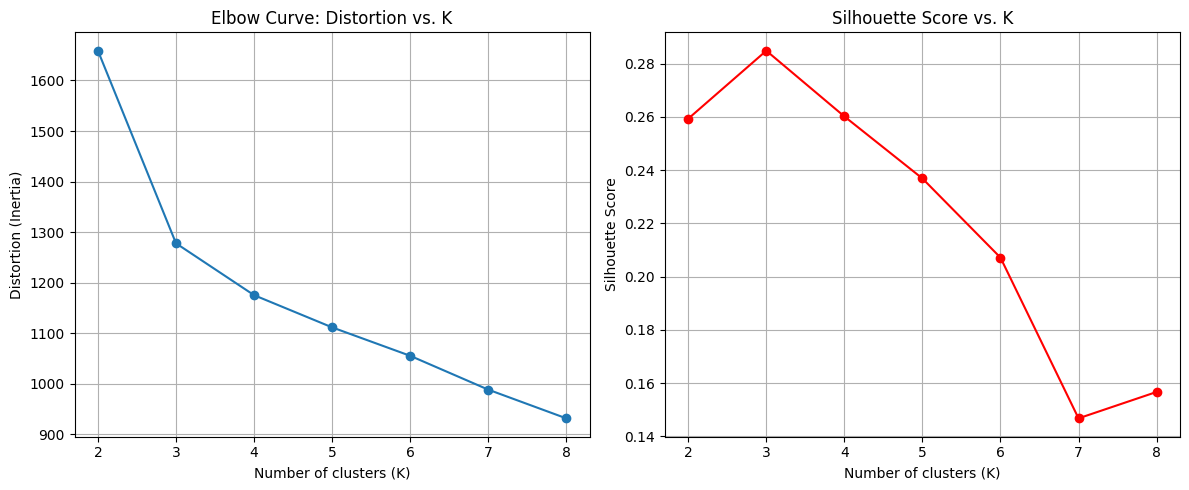

In [9]:
import matplotlib.pyplot as plt

distortions = []
silhouette_scores = []
K_values = [2, 3, 4, 5, 6, 7, 8]

for k in K_values:
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=2026
    )
    kmeans.fit(X_std)

    distortions.append(kmeans.inertia_)
    labels = kmeans.labels_
    silhouette_scores.append(silhouette_score(X_std, labels))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K_values, distortions, marker='o')
plt.title('Elbow Curve: Distortion vs. K')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Distortion (Inertia)')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(K_values, silhouette_scores, marker='o', color='red')
plt.title('Silhouette Score vs. K')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)

plt.tight_layout()
plt.show()

Best K: 3
Maximum Silhouette Score: 0.2849

Final Distortion (J) for K=3: 1277.9285
Cluster sizes for K=3:
0    62
1    65
2    51
Name: count, dtype: int64


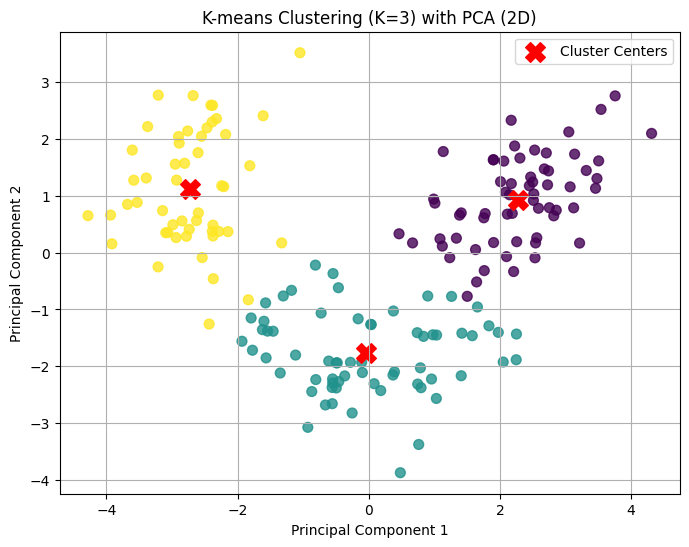

In [10]:
from sklearn.decomposition import PCA

best_K_idx = np.argmax(silhouette_scores)
best_K = K_values[best_K_idx]
max_silhouette_score = silhouette_scores[best_K_idx]

print(f"Best K: {best_K}")
print(f"Maximum Silhouette Score: {round(max_silhouette_score, 4)}\n")

kmeans_best_k = KMeans(
    n_clusters=best_K,
    init='k-means++',
    n_init=10,
    max_iter=300,
    random_state=2026
)
kmeans_best_k.fit(X_std)

final_distortion_J = kmeans_best_k.inertia_
labels_best_k = kmeans_best_k.labels_
cluster_centers_best_k = kmeans_best_k.cluster_centers_

print(f"Final Distortion (J) for K={best_K}: {round(final_distortion_J, 4)}")
print(f"Cluster sizes for K={best_K}:")
print(pd.Series(labels_best_k).value_counts().sort_index())

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_std)
centers_2d = pca.transform(cluster_centers_best_k)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels_best_k, cmap='viridis', s=50, alpha=0.8)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], marker='X', s=200, color='red', label='Cluster Centers')
plt.title(f'K-means Clustering (K={best_K}) with PCA (2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()